In [ ]:
import numpy as np
from scipy.stats import weibull_min, beta

np.random.seed(123)

N = 1000 

weibull_shapes = {
    "Cat1": 1.5,
    "Cat3": 1.8,
    "Cat5": 2.0,
}
weibull_ranges = {
    "Cat1": 10,
    "Cat3": 30,
    "Cat5": 8000,
}
beta_ratios = {
    "Cat2": 0.85,
    "Cat4": 0.92,
}
beta_b = 20 
data = {}

# Weibull categories
for cat in ["Cat1", "Cat3", "Cat5"]:
    k = weibull_shapes[cat]
    raw = weibull_min.rvs(k, size=N)
    scaled = raw / raw.max() * weibull_ranges[cat] # To plot w/ respect to histogram range
    data[cat] = scaled
# Beta categories
for cat in ["Cat2", "Cat4"]:
    r = beta_ratios[cat]
    a = r * beta_b
    b = beta_b
    data[cat] = beta.rvs(a, b, size=N)

# Distribution fitting based on estimated params from parser.calculate.MOM
weibull_fits = {}
for cat in ["Cat1", "Cat3", "Cat5"]:
    shape, loc, scale = weibull_min.fit(data[cat], floc=0)
    weibull_fits[cat] = {
        "shape": shape,
        "scale": scale
    }
beta_fits = {}
for cat in ["Cat2", "Cat4"]:
    a_hat, b_hat, loc, scale = beta.fit(data[cat], floc=0, fscale=1)
    beta_fits[cat] = {
        "a": a_hat,
        "b": b_hat,
    }


print("Weibull fits:")
for k, v in weibull_fits.items():
    print(k, v)

print("\nBeta fits:")
for k, v in beta_fits.items():
    print(k, v)


Weibull fits:
Cat1 {'shape': 1.4854752861057203, 'scale': 2.4125878721698593}
Cat3 {'shape': 1.7842672116200031, 'scale': 10.006323004976807}
Cat5 {'shape': 1.9881883797385616, 'scale': 3232.6436811811755}

Beta fits:
Cat2 {'a': 17.085366802205044, 'b': 19.900423846051243, 'a_over_b': 0.8585428599097512}
Cat4 {'a': 18.388806597407996, 'b': 19.851286190617998, 'a_over_b': 0.9263282197855174}


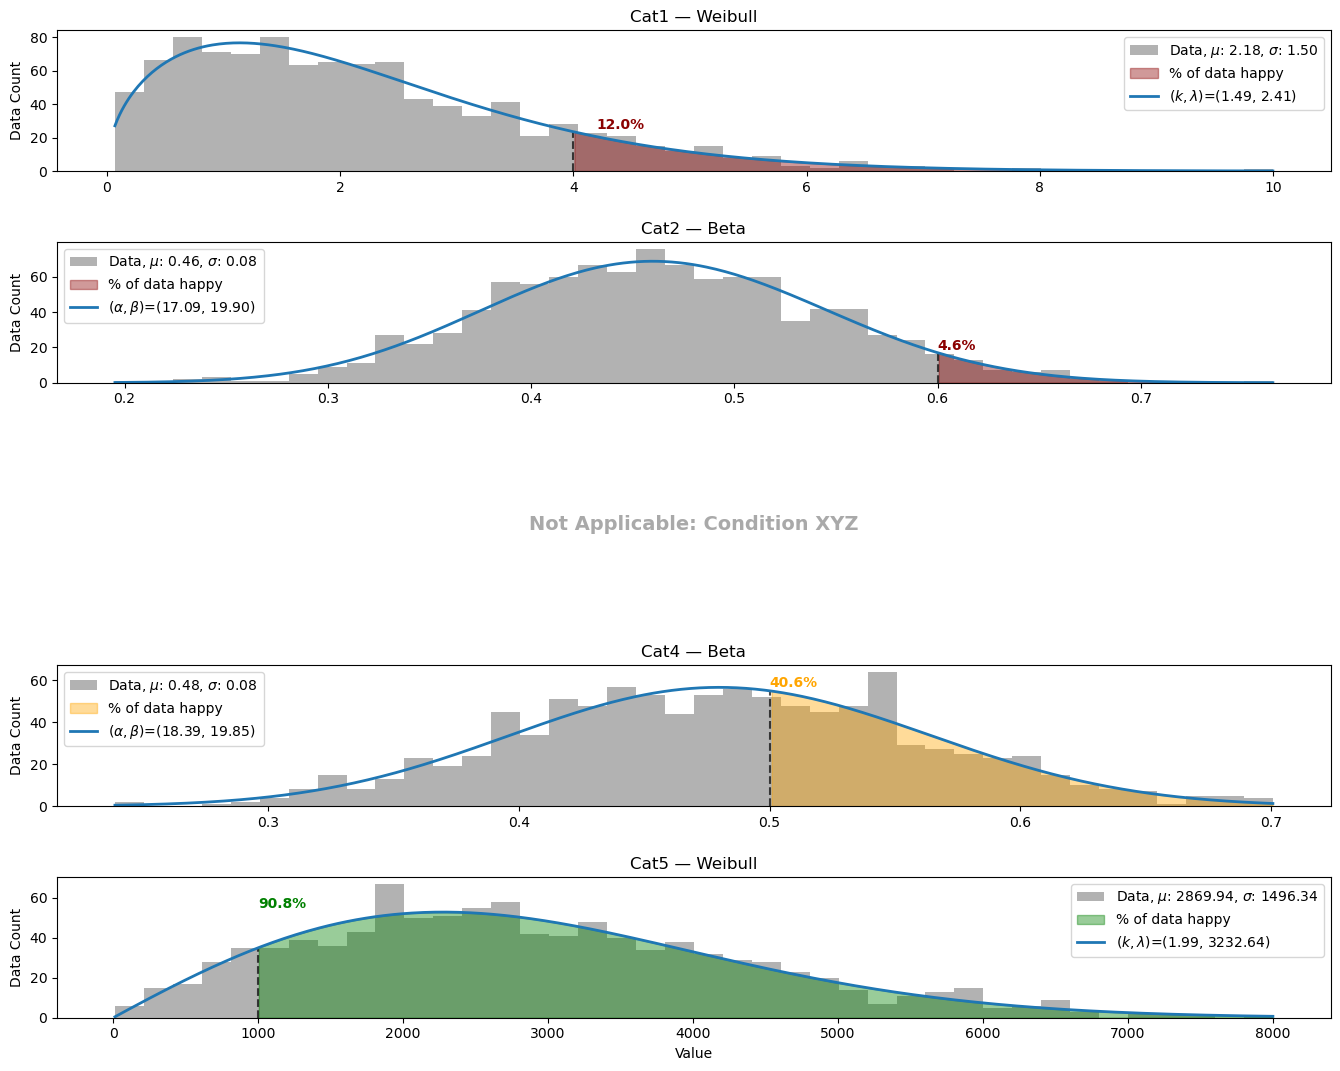

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis # For text placement logic

def happiness_color(p):
    if p >= 0.8:
        return "green"
    elif p >= 0.6:
        return "yellow"
    elif p >= 0.4:
        return "orange"
    elif p >= 0.2:
        return "red"
    elif p > 0:
        return "darkred"
    else:
        return "darkgreen"
    
fig, axes = plt.subplots(5, 1, figsize=(14, 11))
fig.tight_layout(pad=3)

cats = ["Cat1", "Cat2", "Cat3", "Cat4", "Cat5"] # Should be called dynamically from the map 
happy_levels = [4, 0.6, 15, 0.5, 1000]  # same order as cats
not_applicable_conditions = {"Cat3": "Condition XYZ"}

for ax, cat in zip(axes, cats):
    # If there are N/A conditions, show this with the appropriate condition
    if cat in not_applicable_conditions:
        ax.axis('off') 
        ax.text(
            0.5, 0.5,  # Plot center
            f"Not Applicable: {not_applicable_conditions[cat]}",
            ha='center',
            va='center',
            fontweight='bold',
            fontsize=14,
            color='darkgrey',
            transform=ax.transAxes # Correct coordinates
        )
        continue

    x = data[cat]
    N = len(x)
    lvl = happy_levels[cats.index(cat)]
    # Histogram (counts, not density)
    counts, bin_edges, _ = ax.hist(
    x, bins='auto',alpha=0.6, color='gray',
    label=r"Data, $\mu$: %.2f, $\sigma$: %.2f" % (x.mean(), x.std())
    )
    bin_width = bin_edges[1] - bin_edges[0]


    x_grid = np.linspace(x.min(), x.max(), 500)

    # Notional code...plotting fitted distribution
    if cat in ["Cat1", "Cat3", "Cat5"]:
        dist_name = "Weibull"
        params = weibull_fits[cat]
        pdf = weibull_min.pdf(x_grid,
            params["shape"], scale=params["scale"]
        )
        p_above = 1 - weibull_min.cdf(lvl, params["shape"], scale=params["scale"]) # happiness level line
    else: 
        dist_name = "Beta"
        params = beta_fits[cat]
        pdf = beta.pdf(x_grid,
            params["a"], params["b"]
        )
        p_above = 1 - beta.cdf(lvl, params["a"], params["b"]) # happiness level line -- Already in calc.mom (cdf)


    # Highlight area above happiness level
    scaled_pdf = pdf * N * bin_width
    y_lvl = np.interp(lvl, x_grid, scaled_pdf)
    color = happiness_color(p_above)
    ax.fill_between(x_grid, 0, scaled_pdf, where=(x_grid >= lvl), color=color, alpha=0.4, label="% of data happy")
    ax.plot([lvl, lvl], [0, y_lvl], color='black', linestyle='--', alpha=0.7)
    y_lvl = np.interp(lvl, x_grid, scaled_pdf)  # already computed for vertical line

    # Highlight annotation logic
    mask = x_grid >= lvl
    y_shaded_max = scaled_pdf[mask].max()
    x_skew = skew(x) # Ensures text doesn't overlap with shaded area
    # Probably a suboptimal methodology...
    if x_skew > 1:     
        x_text = lvl + 0.02*(x.max() - x.min())
    elif x_skew < -1:    
        x_text = lvl - 0.02*(x.max() - x.min())
    else:                 
        x_text = lvl
    ax.text(
        x_text, 
        y_shaded_max * (1 + 0.01 * max(kurtosis(x), 1)),                   
        f"{100*p_above:.1f}%",ha='left', va='bottom', 
        fontweight='bold',color=color
    )

    # Notional
    if cat in ["Cat1", "Cat3", "Cat5"]:
        ax.plot(
            x_grid,scaled_pdf,linewidth=2,
            label=(
                r"$(k , \lambda)$="
                f"({params['shape']:.2f}, {params['scale']:.2f})"
            )
        )
    else:
        ax.plot(
            x_grid,scaled_pdf,linewidth=2,
           label=(
                r"$(\alpha, \beta)$="
                f"({params['a']:.2f}, {params['b']:.2f})"
            )
        )

    ax.set_title(f"{cat} — {dist_name}")
    ax.set_ylabel("Data Count")
    if cat in ["Cat1", "Cat3", "Cat5"]:
        ax.legend(loc="upper right")
    else:
        ax.legend(loc="upper left")

axes[-1].set_xlabel("Value")
plt.savefig("Proposed Dashboard.png", dpi=400)
plt.show()
